# From the Facebook Hearing's Topic to the Firms It Concerns

| Item | Description |
|---|---|
| Goal | Follow the running example on from T2.5. The Facebook hearing of April 10, 2018 (`CHRG-115shrg37801`) has consumer data privacy legislation as its primary topic. This notebook shows how that topic reaches the firms: the hearing's own statements among the 374 the topic holds, and the policy summary written from them. It then shows the firm summaries of well-known firms and the two panels of Figure 3 of the proposal in one figure. No model is called. |
| Input | `topic68_statements.parquet` (T3.2.1); the policy summary, its run record, and its call log (T3.2.3); `firm_summaries.parquet` (T3.3.5); `firm_relevance.parquet` (T3.4.1). The sector table of T3.4.3 and the selected firms of T3.4.4, under `R - Results/tables`. |
| Output | Readable copies beside this notebook: `01 - Inputs/hearing_statements.md` and `prompts.md`; `02 - Outputs/policy_summary.md`, `selected_firm_summaries.md`, `sector_means.csv`, and `selected_firms.csv`; `03 - Logs and Verification/policy_summary_calls.jsonl` and `verification.json`. The two-panel figure `fig_running_example_topic_relevance` under `R - Results/figures/...`. |
| Run | Executed on 2026-10-31. Every number is read from the stored runs of T3.2 to T3.4. |


## Step 1. Import packages


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.patches import Patch


## Step 2. Define file locations


In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[2]  # <pipeline>/<section>/<subfolder>/ sits three levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.5 - Running Example [Facebook-Cambridge Analytica Scandal Hearing]")
NOTEBOOK_NAME = "T3.5.1 - Example - From the Facebook Hearing's Topic to the Firms It Concerns"  # the notebook filename without .ipynb
RAW_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Raw"
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
PACKAGE = "CHRG-115shrg37801"
TOPIC_ID = 68
T32_INTERIM = SCRATCH_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.2 - Topic Side - Policy Summary of the Legislator Statements" / "Interim"
T32_PROCESSED = SCRATCH_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.2 - Topic Side - Policy Summary of the Legislator Statements" / "Processed"
T33_PROCESSED = SCRATCH_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.3 - Firm Side - Summaries of the 10-K Item 1 Filings" / "Processed"
T34_PROCESSED = SCRATCH_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.4 - Topic Relevance - Score and Figures" / "Processed"
T34_TABLES = PROJECT_FOLDER / "R - Results/tables" / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure/T3.4 - Topic Relevance - Score and Figures"
SECTOR_TABLE = T34_TABLES / "T3.4.3 - Figure - Sector Means and Medians" / "table_naics2_sector_means_and_medians.csv"
SELECTED_TABLE = T34_TABLES / "T3.4.4 - Figure - Selected High and Low Relevance Firms" / "table_selected_firms_marked_list.csv"
EXAMPLE_FOLDER = PROJECT_FOLDER / NOTEBOOK_SUBFOLDER  # the readable copies live beside this notebook
INPUTS_FOLDER = EXAMPLE_FOLDER / "01 - Inputs"
OUTPUTS_FOLDER = EXAMPLE_FOLDER / "02 - Outputs"
LOGS_FOLDER = EXAMPLE_FOLDER / "03 - Logs and Verification"
MIN_FIRMS = 5  # sectors with fewer firms are left out of the left panel, as in T3.4.3
FIRM_SUMMARY_TITLE = "a Firm-Level Summary of 10-K Item 1s"
POLICY_SUMMARY_TITLE = "the Policy Summary of Legislator Statements on Consumer Data Privacy Legislation"
SCORE_TITLE = f"Cosine Similarity Between {FIRM_SUMMARY_TITLE} and {POLICY_SUMMARY_TITLE}"
SCORE_WORDS = ("the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's "
               "yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the "
               "language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. "
               "A higher score means that the firm's business description is closer to the policy summary")
SAMPLE_WORDS = {"three_years": "the three-year sample (fiscal years 2010, 2015, and 2020)", "all_years": "the all-years sample (every fiscal year a firm filed, 1999 to 2025)"}
SOURCE = "10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations"
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/tables" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
MODEL_CACHE = SCRATCH_FOLDER / "cache" / "huggingface"
ENV_FILE = PROJECT_FOLDER / "T - Three Step Text Analysis Pipeline/T3 - Topic Relevance and Corporate Disclosure" / ".env"
for folder in (FIGURE_FOLDER,):
    folder.mkdir(parents=True, exist_ok=True)


## Step 3. Define the prompts

The policy-summary prompts of T3.2.2 and the firm-summary prompts of T3.3.1, unchanged, so the readable copy carries the exact wording of the production runs.


In [3]:
SYSTEM_PROMPT = (
    "You are a policy analyst with a working knowledge of United States congressional hearings. "
    "You report only what the statements say."
)

MAP_PROMPT_TEMPLATE = """Below are {n_statements} statements that members of the House Science and Senate Commerce committees made in hearings held in {year} on the topic "{topic_label}". Each statement is numbered and marked with the legislator's stance toward the topic, support or concern.

--- STATEMENTS ---
{statements_block}
--- END OF STATEMENTS ---

Summarize, in {target_words} words, what the legislation discussed in these statements asks of companies and other organizations and what it tries to regulate: which data practices, which kinds of data, and which actors. Write continuous prose. If the statements say little, write only a sentence or two. Do not list or count the statements, do not name legislators, and do not add knowledge beyond the statements."""

REDUCE_PROMPT_TEMPLATE = """Below are {n_years} summaries, one per year, of statements that members of the House Science and Senate Commerce committees made in hearings held between {year_min} and {year_max} on the topic "{topic_label}". Each summary is marked with its year.

--- YEARLY SUMMARIES ---
{summaries_block}
--- END OF YEARLY SUMMARIES ---

Combine them into one summary of the legislation, in {target_words} words, for a reader who has not seen the statements. Cover two things:
1. What the legislation asks of companies and other organizations: the obligations it imposes on them and the rights it gives consumers.
2. What it tries to regulate: which data practices, which kinds of data, and which actors.

Write continuous prose in one or two paragraphs. Name the specific requirements, data practices, and actors; do not say that the topic is about laws, bills, or privacy in general. Do not add knowledge beyond the yearly summaries."""

SYSTEM_PROMPTS = {
    "map": "You are an expert reader of corporate 10-K filings. You report only what the text states.",
    "collapse": "You are an expert reader of corporate 10-K filings. You condense summaries without adding to them.",
    "reduce": "You are an expert reader of corporate 10-K filings. You write from the summaries given and add nothing that is not in them.",
}

MAP_OPENING = """Below is one consecutive segment of the Item 1 (Business) section of the 10-K that {company} filed for fiscal year {fyear}. The segments are read in order.

--- SEGMENT {segment} OF {n_segments} ---
{text}
--- END OF SEGMENT ---
"""

MAP_TASKS = {
    "summary_without_focus": """Summarize this segment in {target_words} words: what the company does, its products and services, its customers and markets, how it operates, and the regulations it says it is subject to, as this segment states them. Keep the company's own terms. If the segment contains none of these, for example only headings or boilerplate, say so in one sentence.

Write only the summary of the segment above.""",
    "summary_lines_of_business": """Summarize in {target_words} words of continuous prose what this segment says the company's business is: the products, services, or segments it sells or operates, and who its customers are. Do not describe internal activities such as labor relations, fuel purchasing, insurance, financing, or regulatory compliance. If the segment describes no business, say so in one sentence.

Write only the summary of the segment above.""",
    "summary_privacy": """Report in {target_words} words what this segment says about consumer personal data: which activities collect, store, use, share, or sell personal data; whose data it is; and which privacy or data protection laws and regulators it names. If the segment says nothing about personal data or privacy, say so in one sentence.

Write only the report for the segment above.""",
}

COLLAPSE_OPENING = """Below are summaries of consecutive segments of the Item 1 (Business) section of the 10-K that {company} filed for fiscal year {fyear}, in the order they occur. They are already summaries, not the filing text.

--- SEGMENT SUMMARIES ---
{text}
--- END ---
"""

COLLAPSE_TASKS = {
    "summary_without_focus": """Condense them into one account of {target_words} words that keeps what the company does, its products and services, customers and markets, operations, and the regulations named. This is a portion of the section, so do not write an overall conclusion about the company.

Write only the condensed account.""",
    "summary_lines_of_business": """Condense them into one paragraph of {target_words} words that keeps every distinct product, service, or segment named, removing repetition. This is a portion of the section, so do not write an overall conclusion about the company.

Write only the condensed paragraph.""",
    "summary_privacy": """Condense them into one account of {target_words} words that keeps every activity involving personal data, whose data it is, and every privacy law and regulator named, removing repetition. This is a portion of the section, so do not write an overall conclusion about the company.

Write only the condensed account.""",
}

REDUCE_OPENING = """Below are summaries of every segment of the Item 1 (Business) section of the 10-K that {company} filed for fiscal year {fyear}, in order. They are already summaries, not the filing text.

--- SEGMENT SUMMARIES ---
{text}
--- END ---
"""

REDUCE_TASKS = {
    "summary_without_focus": """Write a single summary of the whole section in {target_words} words of continuous prose: what the company does, its products and services, its customers and markets, how it operates, and the regulations it says it is subject to. Keep the company's own terms. Where the segment summaries do not establish one of these, leave it out rather than inferring it.

Write only the summary.""",
    "summary_lines_of_business": """Write one paragraph of {target_words} words of continuous prose describing the company's business as a whole: the products, services, or segments it sells or operates, and who its customers are, with no list, no headings, and no repetition. Include only what the summaries state. Ignore any segment summary that says the segment describes no business. Write about the company only; do not refer to the summaries or to what they do not say. Do not add a closing or general statement.

Write only the paragraph.""",
    "summary_privacy": """Write a single account of the whole section in {target_words} words of continuous prose: how the company's business involves consumer personal data, which activities collect, store, use, share, or sell personal data, whose data it is, and which privacy or data protection laws and regulators are named. If the segment summaries say the section does not mention personal data or privacy, write exactly one sentence saying so and nothing else. Where the segment summaries do not establish something, leave it out rather than inferring it.

Write only the account.""",
}

FIRM_OPENING = """Below are summaries of the Item 1 (Business) sections of the 10-Ks that {company} filed for fiscal years {years}, one per year and marked with its year. They are already summaries, not the filing text.

--- YEARLY SUMMARIES ---
{text}
--- END ---
"""

FIRM_TASKS = {
    "summary_without_focus": """Write a single description of the company's business over these years in {target_words} words of continuous prose: what the company does, its products and services, its customers and markets, how it operates, and the regulations it says it is subject to, noting changes across the years where the summaries show them. Add nothing that is not in the summaries.

Write only the description.""",
    "summary_lines_of_business": """Write one paragraph of {target_words} words of continuous prose describing the company's business across these years, noting changes where the summaries show them, with no list and no repetition. Include only what the summaries state. Write about the company only; do not refer to the summaries or to what they do not say. Do not add a closing or general statement.

Write only the paragraph.""",
    "summary_privacy": """Write a single account in {target_words} words of continuous prose of how the company's business involves consumer personal data across these years: which activities collect, store, use, share, or sell personal data, whose data it is, and which privacy or data protection laws and regulators are named. If the summaries say the filings do not mention personal data or privacy, write exactly one sentence saying so and nothing else. Add nothing that is not in the summaries.

Write only the account.""",
}


## Step 4. Apply the figure style


In [4]:
# Colors from the Figure Style Guide
BLACK = "#000000"
DODGER_BLUE = "#1E90FF"
SLATE_GREY = "#708090"
CRIMSON = "#B31942"  # the proposal's Panel B colours, kept for the right panel
DARK_SLATE = "#5A6B7C"
CYAN = "#00ACC1"
GREY = "#A6A6A8"

# Font and background
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (9, 6)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True

# Horizontal background lines only
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5

# All text and axis lines in BLACK
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

FIGURE_WIDTH, FIGURE_HEIGHT = 9, 6
MARGIN_INCHES = 0.5 / 2.54  # 0.5 cm between each edge of the image and the nearest element
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
BAR_HEIGHT = 0.7
INTERVAL_WIDTHS = {90: 3.2, 95: 1.8, 99: 0.8}


def fit_margins(figure, axis):
    """Move the axes so the Y-title starts 0.5 cm from the left edge, the X-title ends 0.5 cm above the bottom edge, and nothing crosses the right or top margin."""
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    margin = MARGIN_INCHES * figure.dpi
    left_shift = (margin - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
    figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
    figure.canvas.draw()
    bottom_shift = (margin - axis.xaxis.label.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    box = axis.get_tightbbox(renderer)
    right_over = box.x1 - (figure.bbox.width - margin)
    top_over = box.y1 - (figure.bbox.height - margin)
    if right_over > 0 or top_over > 0:
        figure.subplots_adjust(right=figure.subplotpars.right - max(right_over, 0) / figure.bbox.width,
                               top=figure.subplotpars.top - max(top_over, 0) / figure.bbox.height)
        figure.canvas.draw()
    return renderer


def legend_below(figure, axis, handles, labels, ncol=1, fontsize=10):
    """Place the legend with its top 0.5 cm below the X-title and its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room."""
    renderer = fit_margins(figure, axis)
    margin = MARGIN_INCHES * figure.dpi
    axis_box = axis.get_window_extent(renderer)
    center = (axis_box.x0 + axis_box.x1) / 2 / figure.bbox.width
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend = figure.legend(handles, labels, loc="upper center", bbox_to_anchor=(center, (x_title.y0 - margin) / figure.bbox.height),
                           bbox_transform=figure.transFigure, ncol=ncol, frameon=False, handlelength=1.6, fontsize=fontsize)
    figure.canvas.draw()
    bottom_shift = (margin - legend.get_window_extent(renderer).y0) / figure.bbox.height
    figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
    figure.canvas.draw()
    x_title = axis.xaxis.label.get_window_extent(renderer)
    legend.set_bbox_to_anchor((center, (x_title.y0 - margin) / figure.bbox.height), transform=figure.transFigure)
    figure.canvas.draw()
    return legend


def save_figure(figure, stem):
    """Export PNG, SVG, and PDF into the notebook's figure folder."""
    FIGURE_FOLDER.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "svg", "pdf"):
        figure.savefig(FIGURE_FOLDER / f"{stem}.{extension}", dpi=EXPORT_DPI if extension == "png" else None)
    plt.close(figure)
    print(f"saved {stem}.png/.svg/.pdf")


def show_figure(number, title, stem, notes, source):
    """Title, image, Notes, and Source, in that order, as Markdown outside the image."""
    display(Markdown(f"**Figure {number}. {title}**"))
    display(Image(filename=str(FIGURE_FOLDER / f"{stem}.png"), width=900))
    display(Markdown(f"*Notes*: {notes}"))
    display(Markdown(f"*Source*: {source}."))


## Step 5. The hearing's statements among the 374

T2.5 placed 13 of the hearing's stance records under consumer data privacy legislation. They enter the policy summary with the 361 statements of 118 other hearings, with no special weight.


In [5]:
statements = pd.read_parquet(T32_PROCESSED / "topic68_statements.parquet")
hearing_statements = statements.loc[statements["packageId"].eq(PACKAGE)].reset_index(drop=True)
print(f"Topic {TOPIC_ID} statements: {len(statements):,} from {statements['packageId'].nunique()} hearings, {statements['hearing_year'].min()} to {statements['hearing_year'].max()}")
print(f"From the Facebook hearing: {len(hearing_statements)} ({hearing_statements['stance'].value_counts().to_dict()}), {len(hearing_statements) / len(statements):.1%} of the topic")
pd.set_option("display.max_colwidth", 220)
display(hearing_statements[["turn_idx", "bioGuideId", "stance", "text"]])


Topic 68 statements: 374 from 119 hearings, 1999 to 2025
From the Facebook hearing: 13 ({'support': 7, 'concern': 6}), 3.5% of the topic


,turn_idx,bioGuideId,stance,text
0,5,G000386,support,Our policy toward data privacy and security must keep pace with these changes.
1,5,G000386,support,Data privacy should be tethered to consumer needs and expectations.
2,5,G000386,support,"Now, at a minimum, consumers must have the transparency necessary to make an informed decision about whether to share their data and how it can be used. Consumers ought to have clear information, not opaque policies ..."
3,5,G000386,support,The tech industry has an obligation to respond to widespread and growing concerns over data privacy and security and to restore the public's trust.
4,5,G000386,support,"Moreover, Congress must determine if and how we need to strengthen privacy standards to ensure transparency and understanding for the billions of consumers who utilize these products."
5,7,N000032,concern,"If you and other social media companies do not get your act in order, none of us are going to have any privacy anymore. That is what we are facing. We are talking about personally identifiable information that, if no..."
6,7,N000032,concern,We want to know if it is going to be enough. And I hope that will be in the answers today.
7,17,G000386,concern,"Facebook collects massive amounts of data from consumers, including content, networks, contact lists, device information, location, and information from third parties, yet your data policy is only a few pages long an..."
8,60,H000338,concern,"The recent stories about Cambridge Analytica and data mining on social media raise serious concerns about consumer privacy, and naturally, I know you understand that."
9,659,H001075,concern,"I have been here on and off for the last 4 hours that you have been testifying, and I have to tell you that I am concerned about how much Facebook values trust and transparency if we agree that a critical component o..."


## Step 6. The policy summary written from them

The stored run of T3.2.3: 26 map calls, one per hearing year, and one reduce call. The 2018 map call read the Facebook hearing's statements together with the year's other statements.


In [6]:
meta = json.loads((T32_PROCESSED / "policy_summary_meta.json").read_text(encoding="utf-8"))
policy_summary = (T32_PROCESSED / "policy_summary.md").read_text(encoding="utf-8").strip()
calls = pd.read_json(T32_INTERIM / "policy_summary_calls.jsonl", lines=True)
calls = calls.loc[calls["run_started"].eq(meta["run_started"])].reset_index(drop=True)
yearly = pd.read_csv(T32_PROCESSED / "yearly_summaries.csv")
call_2018 = calls.loc[calls["label"].eq("2018")].iloc[0]
assert len(calls) == meta["n_map_calls"] + len(meta["reduce_rounds"]) and all(text in call_2018["user_prompt"] for text in hearing_statements["text"])
print(f"Run {meta['run_started'][:10]} on {meta['gpu']}: {len(calls)} calls; the 2018 map call read {int(yearly.loc[yearly['hearing_year'].eq(2018), 'n_statements'].iloc[0])} statements ({call_2018['n_input_tokens']:,} tokens) and wrote {int(yearly.loc[yearly['hearing_year'].eq(2018), 'n_words'].iloc[0])} words")
display(Markdown(f"**Yearly summary, 2018** ({int(yearly.loc[yearly['hearing_year'].eq(2018), 'n_words'].iloc[0])} words)\n\n" + yearly.loc[yearly["hearing_year"].eq(2018), "summary"].iloc[0]))
display(Markdown(f"**Policy summary** ({meta['final_n_words']} words, {meta['final_n_bge_tokens']} encoder tokens)\n\n" + policy_summary))


Run 2026-10-25 on NVIDIA A40: 27 calls; the 2018 map call read 44 statements (2,463 tokens) and wrote 129 words


**Yearly summary, 2018** (129 words)

The proposed legislation seeks to regulate data collection, retention, sale, and usage practices across the internet ecosystem, specifically targeting social media companies, tech industry actors, drone operators, and federal agencies like the FTC. It requires companies to provide transparent, clear information to consumers rather than opaque policies, ensuring individuals can make informed decisions about sharing their data. The law aims to establish uniform privacy protections regardless of location, incorporating standards similar to the EU's GDPR and California's CCPA. Key requirements include granting consumers ownership rights or opt-out capabilities, mandating breach notifications within 72 hours, and enforcing "privacy by design" principles. The legislation specifically addresses personally identifiable information, including content, contact lists, location, and device data, while demanding that federal agencies actively monitor compliance rather than adopting a hands-off approach.

**Policy summary** (221 words, 274 encoder tokens)

The legislation imposes rigorous obligations on tech giants, broadband providers, healthcare organizations, drone operators, and financial institutions to secure consumer data and prevent its unauthorized sale or misuse. It grants individuals specific rights, including the ability to opt in or out of data collection, demand clear and conspicuous privacy policies, control their digital communications, and establish data "firewalls." Companies are required to implement "privacy by design," provide breach notifications within 72 hours, and ensure that sensitive information such as health records, social security numbers, and geolocation data is protected from discrimination and identity theft.

The regulatory scope targets a wide array of data practices, ranging from the deceptive monitoring of online activities and the unauthorized mapping of consumer movements to the commercialization of private data and the use of algorithms to amplify or suppress content. Specific actors include research centers, third-party aggregators, and federal agencies, with particular emphasis on preventing the export of products and the sharing of personal information without consent. The framework addresses diverse data types, including directory information, voice recordings, and data gathered by connected vehicles, aiming to balance national security interests with civil liberties. Ultimately, the legislation seeks to replace fragmented standards with a uniform national baseline that mandates transparency, enforces accountability, and empowers consumers to make informed choices regarding their personal information in the digital economy.

## Step 7. The firms the topic concerns

The score of T3.4.1 for every firm of the all-years sample, and the firm summaries of the 22 firms that Figure 3 names. Three of them are shown here; all are written to the readable copy.


In [7]:
scores = pd.read_parquet(T34_PROCESSED / "firm_relevance.parquet")
scores = scores.loc[scores["sample"].eq("all_years")].reset_index(drop=True)
sample_mean = float(scores["score"].mean())
selected = pd.read_csv(SELECTED_TABLE, dtype={"gvkey": str, "naics": str})
firm_texts = pd.read_parquet(T33_PROCESSED / "firm_summaries.parquet", columns=["gvkey", "set", "prompt_version", "n_filings", "years", "n_words", "summary"])
firm_texts = firm_texts.loc[firm_texts["set"].eq("all_years") & firm_texts["prompt_version"].eq("item1-mapreduce-1.3")].set_index("gvkey")
selected = selected.merge(firm_texts[["n_filings", "years", "n_words", "summary"]], left_on="gvkey", right_index=True, how="left", validate="one_to_one")
assert selected["summary"].notna().all()
print(f"All-years sample: {len(scores):,} firms; sample mean {sample_mean:.4f}; selected firms {len(selected)}")
for row in selected.loc[selected["display_name"].isin(["Alphabet Inc.", "Meta Platforms", "Pepsi Bottling Group"])].itertuples(index=False):
    print(f"\n=== {row.display_name} | {row.sector} | score {row.score:.3f}, rank {row.rank} of {len(scores):,} | {row.n_filings} filings {row.years[0]}-{row.years[-1]} ===\n{row.summary}")


All-years sample: 1,058 firms; sample mean 0.5121; selected firms 22

=== Alphabet Inc. | Information | score 0.609, rank 8 of 1,058 | 11 filings 2015-2025 ===
Alphabet Inc. operates primarily through Google, generating revenue by delivering relevant online advertising to consumers and advertisers while managing a portfolio of independent businesses known as "Other Bets." Its core product suite includes Search, Android, Maps, Chrome, YouTube, Google Play, and Gmail, which serve over one billion monthly active users globally. The company offers performance advertising where advertisers pay for user engagement, alongside brand advertising featuring video content on YouTube. Over the years, the business expanded to include cloud services, digital content, and hardware devices such as the Pixel phone and Google Home. Revenue streams diversified to encompass digital content sales, hardware device sales, licensing, subscription services, and cloud platform fees. The "Other Bets" portfolio ev

## Step 8. Draw Figure 3: sectors and selected firms

Left: the sector mean minus the sample mean with nested 90, 95, and 99 percent intervals, from the table of T3.4.3. Right: the selected firms' scores minus the sample mean, from T3.4.4, the information sector in CRIMSON as in the proposal. One figure, two panels, the same X scale on each side's own range.


saved fig_running_example_topic_relevance.png/.svg/.pdf


**Figure 1. Topic Relevance Scores for Publicly Listed Firms: Sectors Relative to the Sample Mean (Left) and Selected Firms (Right)**

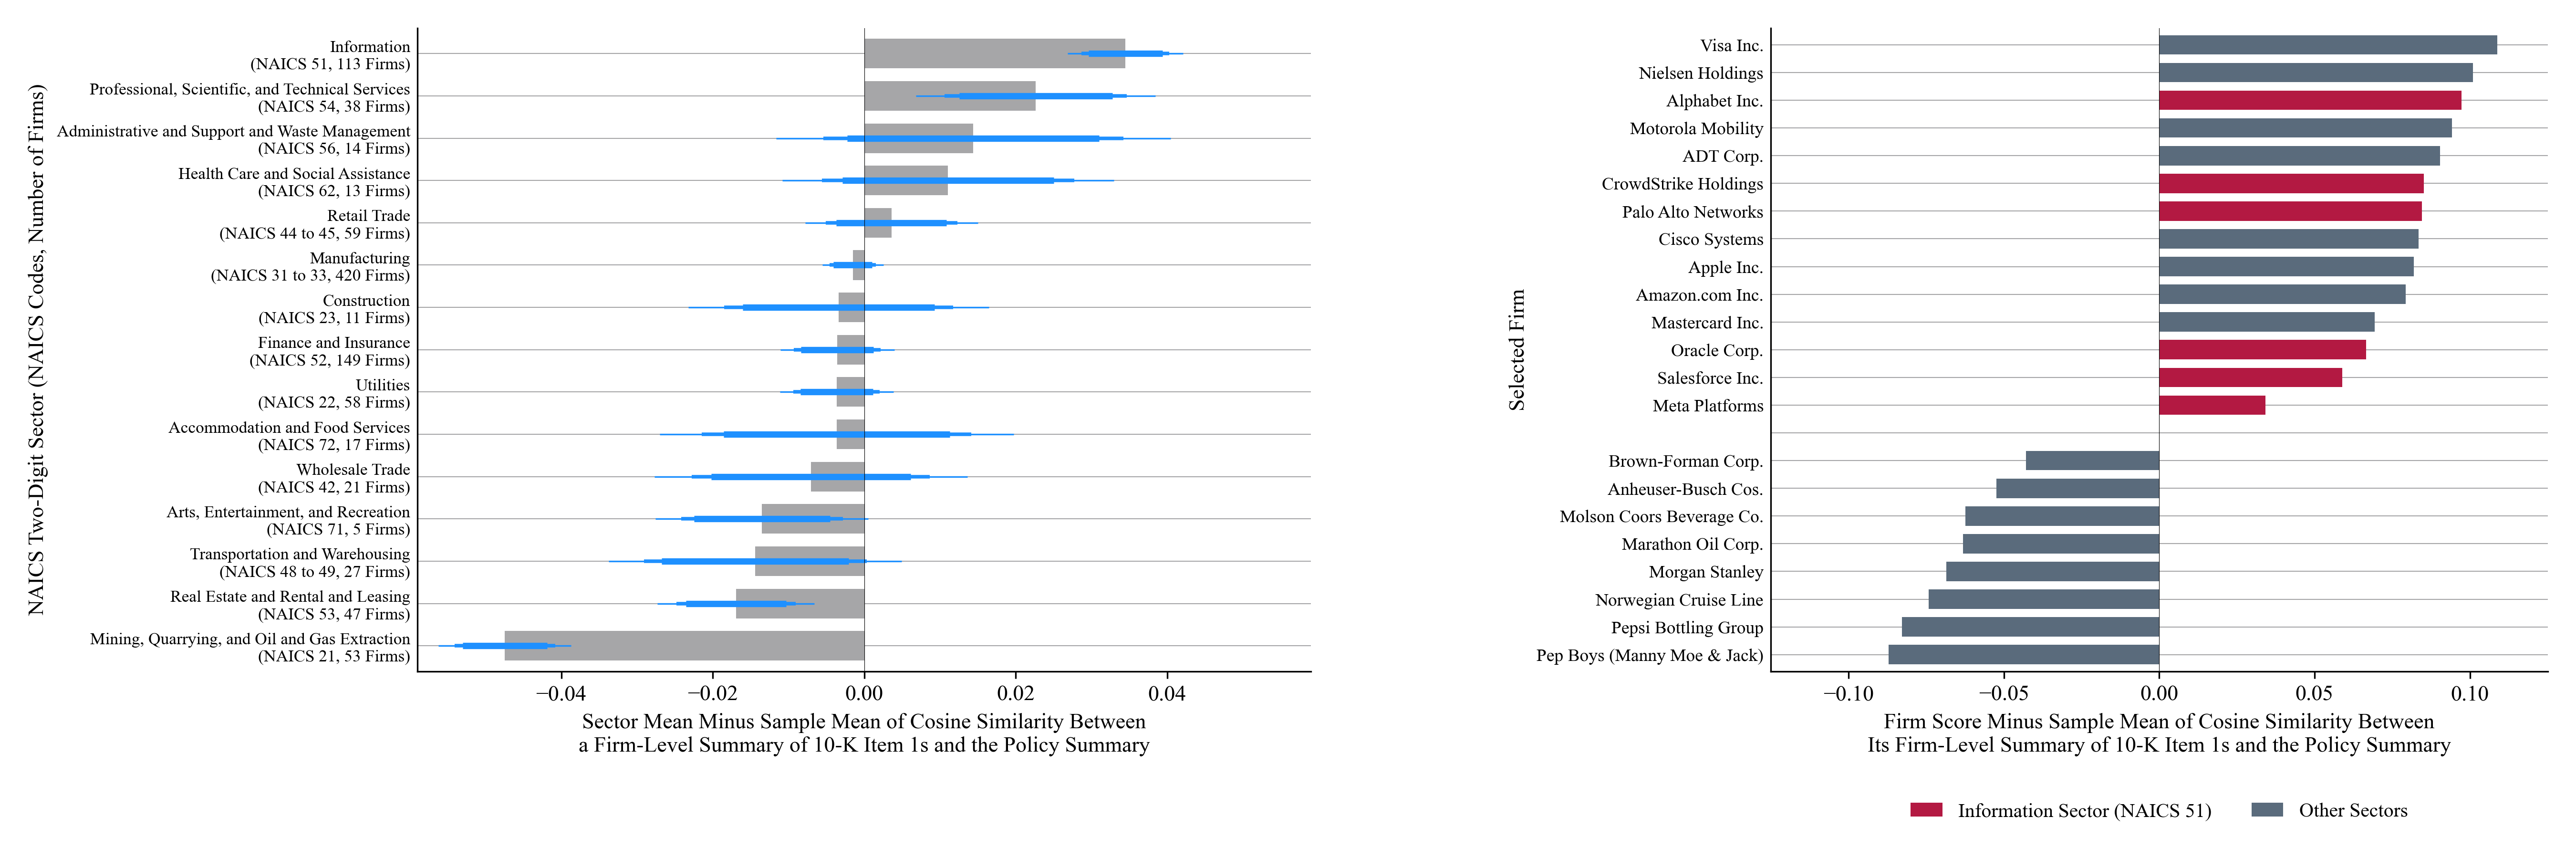

*Notes*: Both panels use the all-years sample (1,058 firms) and the score of T3.4.1, the cosine similarity between two embeddings: the firm-level summary, one paragraph written by the language model that condenses the firm's yearly summaries of its 10-K Item 1 (Business) sections over its fiscal years in the sample, and the policy summary, one text written by the language model that condenses the legislator statements on Topic 68, consumer data privacy legislation, extracted from congressional hearings. A higher score means that the firm's business description is closer to the policy summary. Left: each bar is the sector mean minus the sample mean, 0.512, so that zero is the sample mean; sectors are the firm's Compustat NAICS code cut to two digits, ordered from the highest mean at the top, and sectors with fewer than 5 firms are left out; the three nested lines span the 90, 95, and 99 percent confidence intervals of the sector mean, thickest to thinnest. Right: each bar is the firm's score minus the sample mean for 14 selected high-relevance and 8 selected low-relevance firms, chosen by hand among the 60 highest and 60 lowest scores; red bars are information-sector firms (NAICS 51).

*Source*: 10-K Item 1 sections from SEC EDGAR; congressional hearing statements from GovInfo; NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [8]:
sectors = pd.read_csv(SECTOR_TABLE)
plotted = sectors.loc[sectors["n_firms"].ge(MIN_FIRMS)].sort_values("mean", ascending=False).reset_index(drop=True)
LOWERCASE_WORDS = {"a", "an", "the", "and", "or", "but", "of", "in", "on", "at", "to", "for", "by", "except"}
title_case = lambda name: " ".join(word if word in LOWERCASE_WORDS and i > 0 else word[0].upper() + word[1:] for i, word in enumerate(name.split(" ")))
sector_labels = [f"{title_case(g)}\n(NAICS {c}, {n:,} Firms)" for g, c, n in zip(plotted["group"], plotted["codes"], plotted["n_firms"])]
sector_positions = np.arange(len(plotted))[::-1]
sector_reach = float(max(plotted["mean_ci99_lower"].abs().max(), plotted["mean_ci99_upper"].abs().max())) * 1.05
high = selected.loc[selected["end"].eq("highest")].sort_values("score", ascending=False).reset_index(drop=True)
low = selected.loc[selected["end"].eq("lowest")].sort_values("score", ascending=False).reset_index(drop=True)
firm_labels = high["display_name"].tolist() + [""] + low["display_name"].tolist()
firm_positions = np.arange(len(firm_labels))[::-1]
firm_reach = float(selected["demeaned"].abs().max()) * 1.15
color_of = lambda sector: CRIMSON if sector == "Information" else DARK_SLATE

figure, (left, right) = plt.subplots(1, 2, figsize=(2 * FIGURE_WIDTH, FIGURE_HEIGHT), gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.55})
figure.subplots_adjust(left=0.19, right=1 - MARGIN_INCHES / (2 * FIGURE_WIDTH), top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.22)
left.barh(sector_positions, plotted["mean_minus_sample_mean"], color=GREY, height=BAR_HEIGHT, zorder=2)
for order, level_pct in enumerate([99, 95, 90], start=3):
    below = np.clip(plotted["mean_minus_sample_mean"] - plotted[f"mean_ci{level_pct}_lower"], 0, None)
    above = np.clip(plotted[f"mean_ci{level_pct}_upper"] - plotted["mean_minus_sample_mean"], 0, None)
    left.errorbar(plotted["mean_minus_sample_mean"], sector_positions, xerr=np.vstack([below, above]), fmt="none", ecolor=DODGER_BLUE, elinewidth=INTERVAL_WIDTHS[level_pct], capsize=0, zorder=order)
left.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=6)
left.set_yticks(sector_positions, labels=sector_labels)
left.set_ylim(sector_positions.min() - 0.6, sector_positions.max() + 0.6)
left.set_xlim(-sector_reach, sector_reach)
left.set_xlabel("Sector Mean Minus Sample Mean of Cosine Similarity Between\na Firm-Level Summary of 10-K Item 1s and the Policy Summary")
left.set_ylabel("NAICS Two-Digit Sector (NAICS Codes, Number of Firms)")
left.tick_params(axis="y", length=0, labelsize=8.5)
right.barh(firm_positions[:len(high)], high["demeaned"], color=[color_of(s) for s in high["sector"]], height=BAR_HEIGHT, zorder=2)
right.barh(firm_positions[len(high) + 1:], low["demeaned"], color=[color_of(s) for s in low["sector"]], height=BAR_HEIGHT, zorder=2)
right.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)
right.set_yticks(firm_positions, labels=firm_labels)
right.set_ylim(firm_positions.min() - 0.6, firm_positions.max() + 0.6)
right.set_xlim(-firm_reach, firm_reach)
right.set_xlabel("Firm Score Minus Sample Mean of Cosine Similarity Between\nIts Firm-Level Summary of 10-K Item 1s and the Policy Summary")
right.set_ylabel("Selected Firm")
right.tick_params(axis="y", length=0, labelsize=9)
for axis in (left, right):
    axis.spines[["top", "right"]].set_visible(False)
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin = MARGIN_INCHES * figure.dpi
left_shift = (margin - left.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title = right.xaxis.label.get_window_extent(renderer)
legend = figure.legend([Patch(facecolor=CRIMSON), Patch(facecolor=DARK_SLATE)], ["Information Sector (NAICS 51)", "Other Sectors"], loc="upper center",
                       bbox_to_anchor=((right.get_window_extent(renderer).x0 + right.get_window_extent(renderer).x1) / 2 / figure.bbox.width, (x_title.y0 - margin) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=2, frameon=False, handlelength=1.6, fontsize=10)
figure.canvas.draw()
bottom_shift = (margin - min(legend.get_window_extent(renderer).y0, left.xaxis.label.get_window_extent(renderer).y0)) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title = right.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor(((right.get_window_extent(renderer).x0 + right.get_window_extent(renderer).x1) / 2 / figure.bbox.width, (x_title.y0 - margin) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
save_figure(figure, "fig_running_example_topic_relevance")
notes = (f"Both panels use the all-years sample ({len(scores):,} firms) and the score of T3.4.1, {SCORE_WORDS}. Left: each bar is the sector mean minus the sample mean, {sample_mean:.3f}, "
         f"so that zero is the sample mean; sectors are the firm's Compustat NAICS code cut to two digits, ordered from the highest mean at the top, and sectors with fewer than {MIN_FIRMS} firms are left out; "
         "the three nested lines span the 90, 95, and 99 percent confidence intervals of the sector mean, thickest to thinnest. Right: each bar is the firm's score minus the sample mean for "
         f"{len(high)} selected high-relevance and {len(low)} selected low-relevance firms, chosen by hand among the 60 highest and 60 lowest scores; red bars are information-sector firms (NAICS 51).")
show_figure(1, f"Topic Relevance Scores for Publicly Listed Firms: Sectors Relative to the Sample Mean (Left) and Selected Firms (Right)", "fig_running_example_topic_relevance", notes, SOURCE)


## Step 9. Write the readable copies

The hearing's statements, the prompts, the policy summary, the selected firms with their summaries, the two panel tables, and the call log of the policy summary run.


In [9]:
for folder in (INPUTS_FOLDER, OUTPUTS_FOLDER, LOGS_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)
lines = [f"# The Facebook hearing's statements on consumer data privacy legislation\n", f"The {len(hearing_statements)} stance records that T2.5 placed under topic {TOPIC_ID} for `{PACKAGE}`, "
         f"among the {len(statements):,} statements of the topic from {statements['packageId'].nunique()} hearings. Each line gives the turn, the legislator's Bioguide id, the stance, and the cited sentences.\n"]
lines += [f"- turn {r.turn_idx}, {r.bioGuideId}, **{r.stance}**: {r.text}" for r in hearing_statements.itertuples(index=False)]
(INPUTS_FOLDER / "hearing_statements.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
prompt_text = ["# Prompts of the topic relevance pipeline\n", "## Policy summary prompts\n", "Used by T3.2.3 with `Qwen/Qwen3.5-4B`: one map call per hearing year, then one reduce call.\n",
               "### System prompt\n", SYSTEM_PROMPT + "\n", "### Map prompt template\n", "```\n" + MAP_PROMPT_TEMPLATE + "\n```\n", "### Reduce prompt template\n", "```\n" + REDUCE_PROMPT_TEMPLATE + "\n```\n",
               "## Firm summary prompts\n", "Used by T3.3.2 (map, collapse, reduce) and T3.3.4 (per firm) with `Qwen/Qwen3.5-4B`, family `summary_lines_of_business`, prompt version `item1-mapreduce-1.3`.\n"]
for stage, system_prompt in SYSTEM_PROMPTS.items():
    prompt_text += [f"### System prompt, {stage}\n", system_prompt + "\n"]
for title, opening, task in [("Map (one segment)", MAP_OPENING, MAP_TASKS["summary_lines_of_business"]), ("Collapse (a run of segment summaries)", COLLAPSE_OPENING, COLLAPSE_TASKS["summary_lines_of_business"]),
                             ("Reduce (all segment summaries of a filing)", REDUCE_OPENING, REDUCE_TASKS["summary_lines_of_business"]), ("Per firm (the firm's yearly summaries)", FIRM_OPENING, FIRM_TASKS["summary_lines_of_business"])]:
    prompt_text += [f"### {title}\n", "```\n" + opening + task + "\n```\n"]
(INPUTS_FOLDER / "prompts.md").write_text("\n".join(prompt_text), encoding="utf-8")
(OUTPUTS_FOLDER / "policy_summary.md").write_text(f"# Policy summary, consumer data privacy legislation\n\nWritten by T3.2.3 on {meta['run_started'][:10]} from {len(statements):,} statements; "
                                                 f"{meta['final_n_words']} words, {meta['final_n_bge_tokens']} encoder tokens.\n\n{policy_summary}\n", encoding="utf-8")
firm_lines = [f"# Selected firms and their firm-level summaries\n", f"Score: cosine of the firm summary with the policy summary; sample mean {sample_mean:.4f} over {len(scores):,} firms.\n"]
for r in selected.sort_values("score", ascending=False).itertuples(index=False):
    firm_lines += [f"## {r.display_name} (gvkey {r.gvkey})\n", f"{r.sector} (NAICS {r.naics}); score {r.score:.4f}, rank {r.rank} of {len(scores):,}; {r.n_filings} filings, fiscal {r.years[0]} to {r.years[-1]}; {r.n_words} words.\n", r.summary + "\n"]
(OUTPUTS_FOLDER / "selected_firm_summaries.md").write_text("\n".join(firm_lines), encoding="utf-8")
plotted.to_csv(OUTPUTS_FOLDER / "sector_means.csv", index=False, float_format="%.6f")
selected.drop(columns=["years", "summary"]).to_csv(OUTPUTS_FOLDER / "selected_firms.csv", index=False, float_format="%.6f")
calls.to_json(LOGS_FOLDER / "policy_summary_calls.jsonl", orient="records", lines=True, force_ascii=False)
print("Wrote 01 - Inputs (2 files), 02 - Outputs (4 files), and 03 - Logs and Verification/policy_summary_calls.jsonl")


Wrote 01 - Inputs (2 files), 02 - Outputs (4 files), and 03 - Logs and Verification/policy_summary_calls.jsonl


## Step 10. Check the example

The counts a reader can verify, written to `verification.json`.


In [10]:
meta_row = scores.loc[scores["conm"].eq("META PLATFORMS INC")].iloc[0]
verification = {
    "packageId": PACKAGE, "topic_id": TOPIC_ID, "topic_statements": int(len(statements)), "hearings_with_statements": int(statements["packageId"].nunique()),
    "hearing_statements": int(len(hearing_statements)), "hearing_statements_by_stance": {k: int(v) for k, v in hearing_statements["stance"].value_counts().items()},
    "policy_summary_run": {"run_started": meta["run_started"], "gpu": meta["gpu"], "calls": int(len(calls)), "final_words": meta["final_n_words"], "final_encoder_tokens": meta["final_n_bge_tokens"]},
    "all_years_sample": {"firms": int(len(scores)), "sample_mean": round(sample_mean, 6), "score_min": round(float(scores["score"].min()), 6), "score_max": round(float(scores["score"].max()), 6)},
    "sectors_drawn": int(len(plotted)), "highest_sector": plotted["group"].iloc[0], "lowest_sector_drawn": plotted["group"].iloc[-1],
    "selected_firms": {r.display_name: {"score": round(float(r.score), 6), "rank": int(r.rank), "sector": r.sector} for r in selected.itertuples(index=False)},
    "meta_platforms": {"score": round(float(meta_row["score"]), 6), "rank": int((scores["score"] > meta_row["score"]).sum()) + 1},
    "verification_scope": "every value is read from the stored outputs of T3.2.1, T3.2.3, T3.3.5, T3.4.1, T3.4.3, and T3.4.4; no model is called",
}
(LOGS_FOLDER / "verification.json").write_text(json.dumps(verification, indent=2) + "\n", encoding="utf-8")
assert len(hearing_statements) == 13 and len(statements) == 374 and len(calls) == 27 and len(scores) == 1058 and len(selected) == 22
print(f"1) {len(hearing_statements)} of {len(statements)} statements come from the Facebook hearing; the policy summary has {meta['final_n_words']} words")
print(f"2) {len(plotted)} sectors drawn; highest {plotted['group'].iloc[0]} ({plotted['mean_minus_sample_mean'].iloc[0]:+.3f}), lowest {plotted['group'].iloc[-1]} ({plotted['mean_minus_sample_mean'].iloc[-1]:+.3f})")
print(f"3) Meta Platforms scores {meta_row['score']:.3f}, rank {verification['meta_platforms']['rank']} of {len(scores):,}; the selected firms rank {int(selected['rank'].min())} to {int(selected['rank'].max())}")


1) 13 of 374 statements come from the Facebook hearing; the policy summary has 221 words
2) 15 sectors drawn; highest Information (+0.035), lowest Mining, quarrying, and oil and gas extraction (-0.047)
3) Meta Platforms scores 0.546, rank 186 of 1,058; the selected firms rank 1 to 1053
